# Strategy Analysis — Who Wants to Be a PoliMillionaire?

Evaluates multiple answering strategies across **all competition categories**, running **5 games per category** for each strategy.
Results are saved/merged into `runs_log.json` with structure `{ strategy → { competition → { games, avg_accuracy, avg_earned } } }`.

## 1. Setup

In [63]:
import os
import sys
import random
import time
import json
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import ollama
from datasets import load_dataset
from sentence_transformers import SentenceTransformer

package_parent_dir = os.path.abspath('./')
if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

from millionaire_client import MillionaireClient, AuthenticationError
import dotenv
dotenv.load_dotenv()

username = os.getenv('USER')
pwd      = os.getenv('PASSWORD')
API_URL  = 'http://131.175.15.22:51111/'

client = MillionaireClient(API_URL)
try:
    user = client.login(username, pwd)
    print(f'Login successful. Welcome, {user.username}!')
except AuthenticationError as e:
    print(f'Login failed: {e}')

Login successful. Welcome, Alisss!


In [ ]:
import functools, builtins
# Force flush on every print — buffered output in Jupyter, this fixes.
builtins.print = functools.partial(builtins.print, flush=True)

## 2. Competitions

In [64]:
competitions    = client.competitions.list_all()
COMPETITION_IDS = [c.id for c in competitions]
COMP_NAME       = {c.id: c.name for c in competitions}

print('=== Available Competitions ===')
for comp in competitions:
    print(f'  [{comp.id}] {comp.name} — {comp.max_levels} levels, {comp.question_count} questions')
    if comp.description:
        print(f'       {comp.description}')

=== Available Competitions ===
  [0] Entertainment — 15 levels, 843 questions
       Music, Movies, Celebrities and more
  [1] Ancient History and Politics — 15 levels, 454 questions
       The Roman Empire, The Greeks, and more
  [2] Science and Nature — 15 levels, 5395 questions
       Chemistry, Biology, Physics and similar subjects
  [3] Maths — 15 levels, 390 questions
       Mathematics and Statistics from High School and College


## 3. SemanticQuestionBank

In [ ]:
EMBEDDER = SentenceTransformer('all-MiniLM-L6-v2')


class SemanticQuestionBank:
    """Stores question-answer pairs and retrieves the most similar ones via cosine similarity."""

    def __init__(self, embedder, min_examples=1, top_k=3):
        self.embedder      = embedder
        self.min_examples  = min_examples
        self.top_k         = top_k
        self._pairs        = []
        self._embeddings   = None

    def add(self, question: str, answer: str):
        emb = self.embedder.encode([question], convert_to_numpy=True)
        self._pairs.append((question, answer))
        self._embeddings = emb if self._embeddings is None else np.vstack([self._embeddings, emb])

    def add_batch(self, pairs):
        if not pairs:
            return
        questions = [q for q, _ in pairs]
        embs = self.embedder.encode(questions, convert_to_numpy=True, show_progress_bar=True)
        self._pairs.extend(pairs)
        self._embeddings = embs if self._embeddings is None else np.vstack([self._embeddings, embs])

    def retrieve(self, query: str):
        if len(self._pairs) < self.min_examples:
            return []
        q_emb  = self.embedder.encode([query], convert_to_numpy=True)
        norms  = np.linalg.norm(self._embeddings, axis=1, keepdims=True) + 1e-8
        q_norm = np.linalg.norm(q_emb) + 1e-8
        sims   = (self._embeddings / norms) @ (q_emb / q_norm).T
        top_k  = min(self.top_k, len(self._pairs))
        top_idx = np.argsort(sims[:, 0])[::-1][:top_k]
        return [self._pairs[i] for i in top_idx]

    def checkpoint(self):
        """Snapshot the current state (pairs + embeddings)."""
        return (
            list(self._pairs),
            self._embeddings.copy() if self._embeddings is not None else None,
        )

    def restore(self, state):
        """Restore to a previously saved checkpoint — used to reset between games."""
        pairs, embeddings = state
        self._pairs      = list(pairs)
        self._embeddings = embeddings.copy() if embeddings is not None else None

    def __len__(self):
        return len(self._pairs)


print(f'SemanticQuestionBank ready. Embedder: {EMBEDDER.get_embedding_dimension()}d.')

## 4. Preload MMLU into the Bank

In [ ]:
MMLU_SUBJECTS = [
    'high_school_physics', 'high_school_chemistry', 'high_school_biology',
    'high_school_mathematics', 'high_school_statistics', 'college_mathematics',
    'high_school_world_history', 'high_school_european_history', 'prehistory',
    'high_school_geography', 'sociology', 'high_school_macroeconomics',
    'astronomy', 'anatomy', 'nutrition', 'virology',
    'philosophy', 'logical_fallacies', 'high_school_computer_science',
    'high_school_psychology', 'global_facts', 'miscellaneous',
]
LABELS = ['A', 'B', 'C', 'D']


def preload_mmlu(bank: SemanticQuestionBank, n_per_subject: int = 25):
    pairs = []
    for subject in MMLU_SUBJECTS:
        try:
            ds = load_dataset('cais/mmlu', subject, split='test')
            n  = min(n_per_subject, len(ds))
            for row in ds.select(range(n)):
                idx = row['answer']
                ans = f"{LABELS[idx]}) {row['choices'][idx]}"
                pairs.append((row['question'], ans))
        except Exception as e:
            print(f'  ⚠️  Could not load {subject}: {e}')
    print(f'Loaded {len(pairs)} questions. Embedding...')
    bank.add_batch(pairs)
    print(f'Done. Bank size: {len(bank)}')


semantic_bank = SemanticQuestionBank(EMBEDDER, min_examples=1, top_k=3)
preload_mmlu(semantic_bank, n_per_subject=25)

# Snapshot del bank dopo il preload MMLU — usato per reset tra una partita e l'altra
# così semantic-few-shot non accumula risposte viste in partite precedenti dello stesso run
mmlu_checkpoint = semantic_bank.checkpoint()
print(f'Checkpoint saved: {len(mmlu_checkpoint[0])} pairs (MMLU only)')

## 5. Game Loop Utilities

In [ ]:
N_GAMES = 5               # games per competition per strategy
QUESTIONS_PER_GAME = 15   # max questions per game (used as denominator for accuracy)


def play_game(client, competition_id, strategy_fn, game_index, verbose=True,
              after_answer=None, before_game=None):
    """
    Play one full game and return a summary dict matching the runs_log.json schema.

    before_game  : optional callable() — called before the game starts (e.g. reset the bank).
    after_answer : optional callable(question, chosen_text, result) — e.g. update the bank.
    """
    if before_game:
        before_game()

    game    = client.game.start(competition_id)
    correct = 0
    times   = []

    while game.in_progress:
        q = game.current_question
        if not q:
            break

        t_start     = time.time()
        chosen_id   = strategy_fn(q)
        elapsed     = time.time() - t_start
        chosen_text = next(o.text for o in q.options if o.id == chosen_id)

        result = game.answer(chosen_id)
        times.append(elapsed)
        if result.correct:
            correct += 1

        if after_answer:
            after_answer(q, chosen_text, result)

        if result.game_over:
            break

    accuracy = correct / QUESTIONS_PER_GAME
    avg_time = round(sum(times) / len(times), 3) if times else 0.0

    if verbose:
        icon = '✅' if game.earned_amount > 0 else '❌'
        print(f'    {icon} Game {game_index} | Level {game.current_level} | '
              f'Earned: {game.earned_amount:,.0f} | Acc: {accuracy:.0%}')

    return {
        'game':              game_index,
        'timestamp':         datetime.now().strftime('%Y-%m-%dT%H:%M:%S'),
        'correct':           correct,
        'accuracy':          round(accuracy, 4),
        'earned':            game.earned_amount,
        'reached_level':     game.current_level,
        'response_time_avg': avg_time,
    }


def evaluate_strategy_all_competitions(
    client,
    strategy_fn,
    strategy_name,
    n_games=N_GAMES,
    competition_ids=None,
    verbose=True,
    after_answer=None,
    before_game=None,
):
    """
    Run `n_games` games on every competition.
    Returns a dict: { competition_name: { games, avg_accuracy, avg_earned } }
    """
    if competition_ids is None:
        competition_ids = COMPETITION_IDS

    result = {}
    print(f'\n=== {strategy_name} | {len(competition_ids)} competitions × {n_games} games ===')

    for comp_id in competition_ids:
        comp_name = COMP_NAME[comp_id]
        print(f'  --- {comp_name} ---')
        games = []
        for i in range(1, n_games + 1):
            g = play_game(client, comp_id, strategy_fn, i,
                          verbose=verbose, after_answer=after_answer, before_game=before_game)
            games.append(g)

        result[comp_name] = {
            'games':        games,
            'avg_accuracy': round(sum(g['accuracy'] for g in games) / len(games), 4),
            'avg_earned':   round(sum(g['earned']   for g in games) / len(games), 2),
        }

    return result


print('Utilities loaded.')

## 6. Define Strategies

Each strategy is a `callable(Question) -> option_id (int)`.
Register entries in `STRATEGIES` as `(name, fn, after_answer_fn | None)`.

In [ ]:
import re
import io
import signal
import math as _math
import ast as _ast
import operator as _operator
from contextlib import redirect_stdout

LLAMA   = 'llama3.1:8b'
MISTRAL = 'mistral:7b'
LLAMA_S = 'llama3.2'
MODEL_NAME = LLAMA

VERBOSE = False  # Imposta True per stampare l'output grezzo di ogni chiamata LLM

_MATH_GLOBALS = {
    '__builtins__': __builtins__,
    'math': _math, 'sqrt': _math.sqrt, 'log': _math.log, 'log2': _math.log2,
    'log10': _math.log10, 'exp': _math.exp, 'sin': _math.sin, 'cos': _math.cos,
    'tan': _math.tan, 'pi': _math.pi, 'e': _math.e, 'factorial': _math.factorial,
    'comb': _math.comb, 'perm': _math.perm, 'ceil': _math.ceil, 'floor': _math.floor,
    'abs': abs, 'round': round, 'sum': sum, 'range': range,
}


def _parse_letter(raw: str, question):
    upper = raw.strip().upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m:
        chosen = m.group(1)
    else:
        m = re.search(r'\b([A-D])\b\s*$', upper)
        chosen = m.group(1) if m else None
    if chosen is None:
        for c in reversed(upper):
            if c in LABELS:
                chosen = c
                break
    if chosen is None:
        print(f"  ⚠️  Unparseable: '{raw[:60]}' — random fallback.")
        return random.choice(question.options).id
    return question.options[LABELS.index(chosen)].id


def _llm(prompt: str, max_tokens: int = 200, model: str = None, temperature: float = 0.0) -> str:
    response = ollama.chat(
        model=model or MODEL_NAME,
        messages=[{'role': 'user', 'content': prompt}],
        options={'num_predict': max_tokens, 'temperature': temperature},
    )['message']['content']
    if VERBOSE:
        print(f'\n  ┌── [{model or MODEL_NAME}] ──')
        for line in response.splitlines():
            print(f'  │ {line}')
        print(f'  └──')
    return response


# ── Zero-shot ─────────────────────────────────────────────────────────────
def make_zero_shot_strategy(model: str = None, temperature: float = 0.0):
    m = model or MODEL_NAME
    def strategy(question):
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt = (
            'Answer the following multiple choice question. '
            'Reply with ONLY the letter of the correct answer (A, B, C or D), nothing else.\n\n'
            f'Question: {question.text}\n\n{opts}\n\nAnswer:'
        )
        return _parse_letter(_llm(prompt, max_tokens=10, model=m, temperature=temperature), question)
    strategy.__name__ = f'zero_shot[{m}]'
    return strategy

zero_shot_strategy = make_zero_shot_strategy(LLAMA)


# ── Fixed Chain-of-Thought ─────────────────────────────────────────────────
def make_cot_fixed_strategy(model: str = None, temperature: float = 0.0):
    m = model or MODEL_NAME
    def strategy(question):
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt = (
            'Answer the multiple choice question below.\n'
            'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
            '(X must be A, B, C, or D — nothing else after it)\n\n'
            f'Question: {question.text}\n\n{opts}\n'
        )
        return _parse_letter(_llm(prompt, max_tokens=300, model=m, temperature=temperature), question)
    strategy.__name__ = f'cot_fixed[{m}]'
    return strategy

cot_fixed_strategy = make_cot_fixed_strategy(LLAMA)


# ── Semantic few-shot ──────────────────────────────────────────────────────
def make_semantic_few_shot_strategy(bank: SemanticQuestionBank, model: str = None, temperature: float = 0.0):
    m = model or MODEL_NAME
    def strategy(question):
        opts     = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        examples = bank.retrieve(question.text)
        if examples:
            ex_block = '\n'.join(f'Question: {q}\nAnswer: {a}\n' for q, a in examples)
            prompt = (
                f'Here are some similar questions with correct answers:\n\n{ex_block}\n'
                f'Now answer this question. Reply with ONLY the letter (A, B, C or D).\n\n'
                f'Question: {question.text}\n{opts}\nAnswer:'
            )
        else:
            prompt = (
                'Answer the following multiple choice question. '
                'Reply with ONLY the letter (A, B, C or D), nothing else.\n\n'
                f'Question: {question.text}\n\n{opts}\n\nAnswer:'
            )
        return _parse_letter(_llm(prompt, max_tokens=10, model=m, temperature=temperature), question)
    strategy.__name__ = f'semantic_few_shot[{m}]'
    return strategy

def make_bank_updater(bank: SemanticQuestionBank):
    def after_answer(question, chosen_text, result):
        if result.correct:
            bank.add(question.text, chosen_text)
    return after_answer

semantic_strategy = make_semantic_few_shot_strategy(semantic_bank, LLAMA)


# ── Math Solver ────────────────────────────────────────────────────────────
def _extract_code(raw: str) -> str:
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    if fence:
        return fence.group(1).strip()
    lines = [l for l in raw.strip().splitlines() if not re.match(r'\s*```', l)]
    code  = '\n'.join(lines).strip()
    py_start = re.compile(
        r'^(import |from |def |class |#|print\(|[a-zA-Z_]\w*\s*=|[a-zA-Z_]\w*\s*\()'
    )
    code_lines, found = [], False
    for line in code.splitlines():
        if not found and py_start.match(line.strip()):
            found = True
        if found:
            code_lines.append(line)
    return '\n'.join(code_lines).strip() if code_lines else code


def _run_code(code: str, timeout: int = 10):
    def _handler(signum, frame):
        raise TimeoutError('exec timed out')

    signal.signal(signal.SIGALRM, _handler)
    signal.alarm(timeout)
    try:
        buf = io.StringIO()
        ns  = dict(_MATH_GLOBALS)
        with redirect_stdout(buf):
            exec(code, ns)          # noqa: S102
        return buf.getvalue().strip() or None
    except TimeoutError:
        print(f'  ⚠️  Code timed out after {timeout}s — fallback.')
        return None
    except Exception as e:
        print(f'  ⚠️  Exec error: {e}')
        return None
    finally:
        signal.alarm(0)


_CODE_PROMPT = (
    'Solve the following math problem by writing Python code.\n'
    'STRICT RULES:\n'
    '- Output ONLY a ```python ... ``` code block — no text outside it.\n'
    '- math, sqrt, log, log2, log10, exp, sin, cos, tan, pi, e, factorial, comb, perm '
    'are already available — do NOT import them.\n'
    '- The LAST line MUST be print(<result>) with the final numerical answer.\n\n'
    'Problem: {question}\n\nOptions (context only):\n{options}\n\nPython code:'
)

def make_math_solver_strategy(model: str = None, debug: bool = False):
    m = model or MODEL_NAME
    def strategy(question):
        opts   = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        raw    = _llm(_CODE_PROMPT.format(question=question.text, options=opts), max_tokens=500, model=m)
        code   = _extract_code(raw)
        if debug:
            print(f'\n  ── math-solver debug [{m}] ──')
            print(f'  [raw]:\n{raw[:400]}')
            print(f'  [code]:\n{code}')
        result = _run_code(code)
        if debug:
            print(f'  [exec result]: {result}')
        if result:
            match_prompt = (
                f'A Python script computed this result: {result}\n\n'
                f'Given the following options, which one matches?\n{opts}\n\n'
                f'Reply with ONLY the letter (A, B, C or D):'
            )
            return _parse_letter(_llm(match_prompt, max_tokens=10, model=m), question)
        return make_zero_shot_strategy(m)(question)
    strategy.__name__ = f'math_solver[{m}]'
    return strategy

math_solver_strategy = make_math_solver_strategy(LLAMA)


# ── AST-Safe Calculator ────────────────────────────────────────────────────
_SAFE_OPS = {
    _ast.Add: _operator.add,   _ast.Sub: _operator.sub,
    _ast.Mult: _operator.mul,  _ast.Div: _operator.truediv,
    _ast.Pow: _operator.pow,   _ast.Mod: _operator.mod,
    _ast.FloorDiv: _operator.floordiv,
    _ast.USub: _operator.neg,  _ast.UAdd: _operator.pos,
}
_SAFE_NAMES_CALC = {
    'sqrt': _math.sqrt, 'abs': abs, 'round': round,
    'sin': _math.sin, 'cos': _math.cos, 'tan': _math.tan,
    'log': _math.log, 'log2': _math.log2, 'log10': _math.log10,
    'exp': _math.exp, 'pi': _math.pi, 'e': _math.e,
    'factorial': _math.factorial, 'floor': _math.floor, 'ceil': _math.ceil,
    'comb': _math.comb, 'perm': _math.perm,
}

def _eval_node(node):
    if isinstance(node, _ast.Constant): return node.value
    if isinstance(node, _ast.BinOp):
        op = _SAFE_OPS.get(type(node.op))
        if op is None: raise ValueError('Unsupported op')
        return op(_eval_node(node.left), _eval_node(node.right))
    if isinstance(node, _ast.UnaryOp):
        op = _SAFE_OPS.get(type(node.op))
        if op is None: raise ValueError('Unsupported unary op')
        return op(_eval_node(node.operand))
    if isinstance(node, _ast.Call):
        fn_name = node.func.id if isinstance(node.func, _ast.Name) else None
        fn = _SAFE_NAMES_CALC.get(fn_name)
        if fn is None: raise ValueError(f'Unsupported fn: {fn_name}')
        return fn(*[_eval_node(a) for a in node.args])
    if isinstance(node, _ast.Name):
        val = _SAFE_NAMES_CALC.get(node.id)
        if val is not None: return val
        raise ValueError(f'Unknown name: {node.id}')
    raise ValueError(f'Unsupported node: {type(node).__name__}')

def safe_eval(expr: str):
    try:
        return float(_eval_node(_ast.parse(expr.strip(), mode='eval').body))
    except Exception as ex:
        print(f'  [calc] {ex}')
        return None

_CALC_PROMPT = (
    'You are solving a math multiple-choice question.\n'
    'If a computation is needed, write it on ONE line as:\n'
    '    COMPUTE: <python expression>\n'
    'Supported: +,-,*,/,**,%,sqrt(),factorial(),comb(),sin(),cos(),log(),floor(),ceil(),pi,e\n'
    'Then reason briefly and end with:\n'
    '    Answer: X  (X = A, B, C, or D — nothing after it)\n\n'
    'Question: {question}\n\n{options}\n'
)

def make_calc_strategy(model: str = None, debug: bool = False):
    m = model or MODEL_NAME
    def strategy(question):
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        resp = _llm(_CALC_PROMPT.format(question=question.text, options=opts), max_tokens=400, model=m)
        if debug:
            print(f'\n  ── calculator debug [{m}] ──\n  [response]:\n{resp[:400]}')
        calc_match = re.search(r'COMPUTE:\s*(.+)', resp, re.IGNORECASE)
        if calc_match:
            result = safe_eval(calc_match.group(1).strip())
            if result is not None:
                print(f'  🔢 {calc_match.group(1).strip()} = {result}')
                resp = _llm(
                    f'Given: {calc_match.group(1).strip()} = {result}\n\n'
                    f'Reply with ONLY the letter (A, B, C, or D).\n\n'
                    f'Question: {question.text}\n\n{opts}\n\nAnswer:',
                    max_tokens=10, model=m,
                )
        return _parse_letter(resp, question)
    strategy.__name__ = f'calculator[{m}]'
    return strategy

calc_strategy = make_calc_strategy(LLAMA)


# ── Hybrid Math ────────────────────────────────────────────────────────────
_IS_COMPUTATION_PROMPT = (
    'Does the following math question require numerical computation to answer '
    '(arithmetic, algebra, calculus, statistics)? '
    'Or is it a pure theory/definition/concept question?\n'
    'Reply with exactly one word: COMPUTE or THEORY.\n\n'
    'Question: {question}'
)
_COMPUTATION_KEYWORDS = re.compile(
    r'\b(\d[\d\.,]*|calculate|compute|evaluate|solve|find the value|how many|'
    r'probability|integral|derivative|limit|sum of|product of|percent|'
    r'mean|variance|standard deviation|expected value)\b',
    re.IGNORECASE,
)

def _is_computation_question(question, model: str) -> bool:
    text = question.text + ' ' + ' '.join(o.text for o in question.options)
    if _COMPUTATION_KEYWORDS.search(text):
        return True
    resp = _llm(_IS_COMPUTATION_PROMPT.format(question=question.text), max_tokens=5, model=model)
    return 'COMPUTE' in resp.strip().upper()

def _match_value_to_option(computed: str, question):
    try:
        val = float(computed.replace(',', '').strip())
    except ValueError:
        return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        nums = re.findall(r'-?\d[\d\.,/]*(?:\.\d+)?', opt.text.replace(',', ''))
        for n in nums:
            try:
                opt_val = float(n.split('/')[0]) / float(n.split('/')[1]) if '/' in n else float(n)
                diff = abs(val - opt_val) / (abs(opt_val) + 1e-9)
                if diff < best_diff:
                    best_diff, best_id = diff, opt.id
            except (ValueError, ZeroDivisionError):
                continue
    return best_id if best_diff < 0.01 else None

def make_hybrid_math_strategy(model: str = None, debug: bool = False):
    m = model or MODEL_NAME
    def strategy(question):
        is_comp = _is_computation_question(question, m)
        if debug:
            print(f'\n  ── hybrid [{m}] → {"COMPUTE" if is_comp else "THEORY"} ──')
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        cot_prompt = (
            'Answer the multiple choice question below.\n'
            'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
            '(X must be A, B, C, or D — nothing else after it)\n\n'
            f'Question: {question.text}\n\n{opts}\n'
        )
        if not is_comp:
            resp = _llm(cot_prompt, max_tokens=300, model=m)
            if debug:
                print(f'  [CoT]: {resp[:200]}')
            return _parse_letter(resp, question)
        raw    = _llm(_CODE_PROMPT.format(question=question.text, options=opts), max_tokens=500, model=m)
        code   = _extract_code(raw)
        result = _run_code(code)
        if debug:
            print(f'  [code]:\n{code}\n  [result]: {result}')
        if result:
            matched = _match_value_to_option(result, question)
            if matched is not None:
                return matched
            match_prompt = (
                f'A Python script computed: {result}\n\n'
                f'Which option matches?\n{opts}\n\nReply with ONLY the letter (A, B, C or D):'
            )
            return _parse_letter(_llm(match_prompt, max_tokens=10, model=m), question)
        return _parse_letter(_llm(cot_prompt, max_tokens=300, model=m), question)
    strategy.__name__ = f'hybrid_math[{m}]'
    return strategy


# ── Registry ──────────────────────────────────────────────────────────────
STRATEGIES = [
    ('zero-shot',
     make_zero_shot_strategy(LLAMA),
     None, None, None),

    ('cot-fixed',
     make_cot_fixed_strategy(LLAMA),
     None, None, None),

    ('semantic-few-shot',
     make_semantic_few_shot_strategy(semantic_bank, LLAMA),
     make_bank_updater(semantic_bank),
     None,
     lambda: semantic_bank.restore(mmlu_checkpoint)),

    ('math-solver',
     make_math_solver_strategy(LLAMA),
     None, [3], None),

    ('calculator',
     make_calc_strategy(LLAMA),
     None, [3], None),

    # ('mistral-zero-shot',
    #  make_zero_shot_strategy(MISTRAL),
    #  None, None, None),

    # ('mistral-math-solver',
    #  make_math_solver_strategy(MISTRAL),
    #  None, [3], None),

    # ('mistral-calculator',
    #  make_calc_strategy(MISTRAL),
    #  None, [3], None),

    ('hybrid-math-llama',
     make_hybrid_math_strategy(LLAMA),
     None, [3], None),

    # ('hybrid-math-mistral',
    #  make_hybrid_math_strategy(MISTRAL),
    #  None, [3], None),
]

print('Strategies defined (all with temperature=0):')
for name, _, _, comp_ids, _ in STRATEGIES:
    scope = 'all' if comp_ids is None else f'comp={comp_ids}'
    print(f'  • {name:<28} [{scope}]')

## 6b. Ensemble Strategy

Each question is sent to all three models independently (at temperature=0). The option with the most votes wins. In case of a 3-way tie (all models disagree), `llama3.1:8b` acts as tiebreaker — it's the largest and most reliable model available locally.

This directly addresses the high variance issue: a single model can flip between runs, but three independent models agreeing on the same answer is a much stronger signal.

## 6b.1 DeepSeek-R1 — Thinking Model

`deepseek-r1:1.5b` is a "thinking" model — before answering it generates an internal chain of reasoning (visible as `<think>...</think>` tags). This directly answers one of the assignment's research questions: *"Are thinking models better at answering questions than non-thinking ones?"*

We test it on the Maths competition where reasoning ability matters most.

In [ ]:
DEEPSEEK = 'deepseek-r1:1.5b'

# DeepSeek-R1 outputs <think>...</think> before the answer — strip it before parsing.
def make_deepseek_strategy(temperature: float = 0.0):
    def strategy(question):
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt = (
            'Answer the following multiple choice question.\n'
            'Reply with ONLY the letter of the correct answer (A, B, C or D) on the last line.\n\n'
            f'Question: {question.text}\n\n{opts}\n\nAnswer:'
        )
        raw = _llm(prompt, max_tokens=600, model=DEEPSEEK, temperature=temperature)
        # Strip <think>...</think> block before parsing the letter.
        clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
        return _parse_letter(clean, question)
    strategy.__name__ = f'deepseek_r1[{DEEPSEEK}]'
    return strategy


STRATEGIES += [
    ('deepseek-r1-thinking',
     make_deepseek_strategy(),
     None, [3], None),
]

print(f'DeepSeek-R1 strategy added. Model: {DEEPSEEK}')
print(f'Total strategies in registry: {len(STRATEGIES)}')

In [ ]:
# ── Stampa output grezzo di un modello su una domanda reale ──────────────
# Avvia una partita, prende la prima domanda e stampa cosa pensa ogni modello.

_test_game = client.game.start(3)  # 3 = Maths
_q = _test_game.current_question

print(f'Domanda: {_q.text}')
print('Opzioni:')
for i, opt in enumerate(_q.options):
    print(f'  {LABELS[i]}) {opt.text}')
print()

_opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(_q.options))
_prompt = (
    'Answer the following multiple choice question.\n'
    'Reason step by step, then end with: Answer: X (X = A, B, C or D)\n\n'
    f'Question: {_q.text}\n\n{_opts}\n'
)

for _model in [LLAMA, LLAMA_S, DEEPSEEK]:
    print(f'{"─"*60}')
    print(f'Modello: {_model}')
    _raw = _llm(_prompt, max_tokens=2000, model=_model, temperature=0.0)
    # Per deepseek, mostra anche il thinking separato
    _think = re.search(r'<think>(.*?)</think>', _raw, re.DOTALL)
    if _think:
        print(f'[THINK]:\n{_think.group(1).strip()[:600]}')
        _clean = re.sub(r'<think>.*?</think>', '', _raw, flags=re.DOTALL).strip()
        print(f'[RISPOSTA]: {_clean}')
    else:
        print(f'[OUTPUT]:\n{_raw}')
    print()

In [ ]:
def make_ensemble_strategy(models=None, tiebreaker=None):
    """
    Majority-vote ensemble across multiple models (all at temperature=0).
    Tiebreaker model used when no majority exists — most reliable model it should be.
    """
    _models     = models     or [LLAMA, MISTRAL, LLAMA_S]
    _tiebreaker = tiebreaker or LLAMA

    def strategy(question):
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt = (
            'Answer the following multiple choice question. '
            'Reply with ONLY the letter of the correct answer (A, B, C or D), nothing else.\n\n'
            f'Question: {question.text}\n\n{opts}\n\nAnswer:'
        )
        votes = {}
        for m in _models:
            raw = _llm(prompt, max_tokens=10, model=m, temperature=0.0)
            opt_id = _parse_letter(raw, question)
            votes[opt_id] = votes.get(opt_id, 0) + 1

        # Majority: option with most votes, return we do.
        max_votes = max(votes.values())
        winners   = [opt_id for opt_id, v in votes.items() if v == max_votes]

        if len(winners) == 1:
            return winners[0]

        # Tie — ask the tiebreaker model directly.
        raw = _llm(prompt, max_tokens=10, model=_tiebreaker, temperature=0.0)
        return _parse_letter(raw, question)

    strategy.__name__ = f'ensemble[{"+".join(_models)}]'
    return strategy


# Register ensemble — runs on all competitions.
STRATEGIES += [
    ('ensemble-3',
     make_ensemble_strategy([LLAMA, MISTRAL, LLAMA_S], tiebreaker=LLAMA),
     None, None, None),
]

print('Ensemble strategy added.')
print(f'Models: {LLAMA} + {MISTRAL} + {LLAMA_S}  |  tiebreaker: {LLAMA}')
print(f'Total strategies in registry: {len(STRATEGIES)}')

In [ ]:
# Debug run — 1 game on Maths, verbose output for both models.
# Understand the failure modes, this will help us.
print('=== math-solver DEBUG — llama3.1:8b ===')
debug_solver_llama = make_math_solver_strategy(LLAMA, debug=True)
play_game(client, 3, debug_solver_llama, game_index=0, verbose=True)

print('\n\n=== math-solver DEBUG — mistral:7b ===')
debug_solver_mistral = make_math_solver_strategy(MISTRAL, debug=True)
play_game(client, 3, debug_solver_mistral, game_index=0, verbose=True)

print('\n\n=== calculator DEBUG — llama3.1:8b ===')
debug_calc_llama = make_calc_strategy(LLAMA, debug=True)
play_game(client, 3, debug_calc_llama, game_index=0, verbose=True)

## 6c. Hybrid Math Strategy

The debug reveals two failure modes:
1. **Computation questions**: `math-solver` runs code but the second LLM call (match computed value → option) is unreliable.
2. **Theory questions** (abstract algebra, group theory, logic): no computation needed — `calculator` never emits `COMPUTE:` and the response can't be parsed.

Fix: a **hybrid strategy** that first classifies the question type, then routes to the right approach:
- Theory → `cot-fixed` (reasoning, no code)
- Computation → `math-solver` with **direct value matching** instead of a second LLM call

In [ ]:
import re as _re

_IS_COMPUTATION_PROMPT = (
    'Does the following math question require numerical computation to answer '
    '(arithmetic, algebra, calculus, statistics)? '
    'Or is it a pure theory/definition/concept question?\n'
    'Reply with exactly one word: COMPUTE or THEORY.\n\n'
    'Question: {question}'
)

_COMPUTATION_KEYWORDS = re.compile(
    r'\b(\d[\d\.,]*|calculate|compute|evaluate|solve|find the value|how many|'
    r'probability|integral|derivative|limit|sum of|product of|percent|'
    r'mean|variance|standard deviation|expected value)\b',
    re.IGNORECASE,
)

def _is_computation_question(question, model: str) -> bool:
    # Fast heuristic first — avoid LLM call when obvious it is.
    text = question.text + ' ' + ' '.join(o.text for o in question.options)
    if _COMPUTATION_KEYWORDS.search(text):
        return True
    # LLM classifier for ambiguous cases.
    resp = _llm(
        _IS_COMPUTATION_PROMPT.format(question=question.text),
        max_tokens=5, model=model,
    ).strip().upper()
    return 'COMPUTE' in resp


def _match_value_to_option(computed: str, question):
    """Try to parse the computed result and compare directly to option texts."""
    try:
        val = float(computed.replace(',', '').strip())
    except ValueError:
        return None

    best_id, best_diff = None, float('inf')
    for opt in question.options:
        # Extract first number found in the option text.
        nums = re.findall(r'-?\d[\d\.,/]*(?:\.\d+)?', opt.text.replace(',', ''))
        for n in nums:
            try:
                # Handle fractions like 1/3.
                if '/' in n:
                    num, den = n.split('/')
                    opt_val = float(num) / float(den)
                else:
                    opt_val = float(n)
                diff = abs(val - opt_val) / (abs(opt_val) + 1e-9)
                if diff < best_diff:
                    best_diff, best_id = diff, opt.id
            except (ValueError, ZeroDivisionError):
                continue

    # Accept match only if within 1% relative error — noise-robust this is.
    return best_id if best_diff < 0.01 else None


def make_hybrid_math_strategy(model: str = None, debug: bool = False):
    """
    Routes each math question to the best solver:
    - Computation → math-solver with direct value matching.
    - Theory       → cot-fixed (reasoning, no code).
    """
    m = model or MODEL_NAME

    def strategy(question):
        is_comp = _is_computation_question(question, m)
        if debug:
            qtype = 'COMPUTE' if is_comp else 'THEORY'
            print(f'\n  ── hybrid [{m}] → {qtype} ──')

        if not is_comp:
            # Theory question — reason carefully, the model must.
            opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
            prompt = (
                'Answer the multiple choice question below.\n'
                'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
                '(X must be A, B, C, or D — nothing else after it)\n\n'
                f'Question: {question.text}\n\n{opts}\n'
            )
            resp = _llm(prompt, max_tokens=300, model=m)
            if debug:
                print(f'  [CoT response]: {resp[:200]}')
            return _parse_letter(resp, question)

        # Computation question — generate and run code, then match value directly.
        opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        raw  = _llm(_CODE_PROMPT.format(question=question.text, options=opts), max_tokens=500, model=m)
        code = _extract_code(raw)
        if debug:
            print(f'  [code]:\n{code}')
        result = _run_code(code)
        if debug:
            print(f'  [exec result]: {result}')

        if result:
            # Try direct numeric match first — more reliable than a second LLM call.
            matched_id = _match_value_to_option(result, question)
            if matched_id is not None:
                if debug:
                    print(f'  [direct match] → option {matched_id}')
                return matched_id
            # Fallback: ask LLM to match.
            match_prompt = (
                f'A Python script computed: {result}\n\n'
                f'Which option matches this value?\n{opts}\n\n'
                f'Reply with ONLY the letter (A, B, C or D):'
            )
            return _parse_letter(_llm(match_prompt, max_tokens=10, model=m), question)

        # Code failed — fall back to CoT.
        if debug:
            print('  ⚠️  Code failed — CoT fallback.')
        opts_text = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt = (
            'Answer the multiple choice question below.\n'
            'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
            '(X must be A, B, C, or D — nothing else after it)\n\n'
            f'Question: {question.text}\n\n{opts_text}\n'
        )
        return _parse_letter(_llm(prompt, max_tokens=300, model=m), question)

    strategy.__name__ = f'hybrid_math[{m}]'
    return strategy


# Add hybrid strategies to the registry.
STRATEGIES += [
    ('hybrid-math-llama',
     make_hybrid_math_strategy(LLAMA),
     None, [3], None),

    ('hybrid-math-mistral',
     make_hybrid_math_strategy(MISTRAL),
     None, [3], None),
]

print('Hybrid math strategies added.')
print('Total strategies:', len(STRATEGIES))
for name, _, _, comp_ids, _ in STRATEGIES:
    scope = 'all' if comp_ids is None else f'comp={comp_ids}'
    print(f'  • {name:<28} [{scope}]')

# Quick debug run — 1 game each.
print('\n=== hybrid-math-llama DEBUG ===')
play_game(client, 3, make_hybrid_math_strategy(LLAMA, debug=True), game_index=0, verbose=True)

print('\n=== hybrid-math-mistral DEBUG ===')
play_game(client, 3, make_hybrid_math_strategy(MISTRAL, debug=True), game_index=0, verbose=True)

## 6d. Fine-tuned Llama 3.1 8B

Llama 3.1 8B (4-bit) fine-tuned via LoRA on 7 MMLU math subjects using `mlx-lm`.
The adapter was fused into the base model and saved locally.

Training details:
- **Dataset**: MMLU (abstract_algebra, college_mathematics, high_school_mathematics, high_school_statistics, elementary_mathematics, college_physics, high_school_physics) — 1,274 train / 138 val examples
- **Rationales**: chain-of-thought explanations generated by the base model and included as training targets
- **LoRA**: 16 layers, lr=1e-5, 1000 steps, batch size 4
- **Held-out evaluation**: 70.21% on 47 real PoliMillionaire questions (never seen during training)

Evaluated only on the Maths competition (`comp_ids=[3]`) since the fine-tuning targeted math/statistics subjects.

In [ ]:
from mlx_lm import load as _mlx_load, generate as _mlx_generate

_FT_MODEL_PATH = '/Users/aliceberta/Development/fine-tuning/modello_fuso'

_FT_SYSTEM_PROMPT = (
    'You are a mathematics expert. '
    'Given a multiple-choice question with four options (A, B, C, D), '
    'respond with only the letter of the correct answer, nothing else.'
)


def _ft_format_prompt(question_text: str, opts_str: str) -> str:
    """Exact Llama 3.1 chat template used during fine-tuning."""
    user_msg = f'Question: {question_text}\n{opts_str}'
    return (
        '<|begin_of_text|>'
        '<|start_header_id|>system<|end_header_id|>\n\n'
        f'{_FT_SYSTEM_PROMPT}<|eot_id|>'
        '<|start_header_id|>user<|end_header_id|>\n\n'
        f'{user_msg}<|eot_id|>'
        '<|start_header_id|>assistant<|end_header_id|>\n\n'
    )


def _ft_extract_letter(text: str):
    """Handles both 'correct answer is X' (rationale output) and bare letter."""
    m = re.search(r'correct answer is\s+([ABCD])', text, re.IGNORECASE)
    if m:
        return m.group(1).upper()
    for ch in text.strip().upper():
        if ch in 'ABCD':
            return ch
    return None


print('Loading fine-tuned model...')
_ft_model, _ft_tokenizer = _mlx_load(_FT_MODEL_PATH)
print(f'Fine-tuned model loaded: {_FT_MODEL_PATH}')


def make_finetuned_strategy():
    def strategy(question):
        opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
        prompt   = _ft_format_prompt(question.text, opts_str)
        output   = _mlx_generate(_ft_model, _ft_tokenizer, prompt=prompt, max_tokens=450, verbose=False)
        letter   = _ft_extract_letter(output)
        if letter is None:
            print(f"  ⚠️  Unparseable: '{output[:60]}' — random fallback.")
            return random.choice(question.options).id
        return question.options[LABELS.index(letter)].id
    strategy.__name__ = 'finetuned_llama31_math'
    return strategy


STRATEGIES += [
    ('finetuned-llama31',
     make_finetuned_strategy(),
     None, [3], None),
]

print(f'Fine-tuned strategy added. Total strategies: {len(STRATEGIES)}')

## 7. Run Evaluation

Each strategy plays **5 games on every competition category**.
Results are merged into `runs_log.json`.

In [ ]:
LOG_FILE = 'runs_log.json'

# Load existing log (or start fresh)
if os.path.exists(LOG_FILE):
    with open(LOG_FILE, 'r', encoding='utf-8') as f:
        runs_log = json.load(f)
    print(f'Loaded existing log: {list(runs_log.keys())}')
else:
    runs_log = {}
    print('Starting fresh log.')

# Migrate old structure { games, avg_accuracy, avg_earned } -> { runs: [...] }
for strategy_name, comps in runs_log.items():
    for comp_name, data in comps.items():
        if 'runs' not in data:
            runs_log[strategy_name][comp_name] = {
                'runs': [{
                    'run_id':       1,
                    'games':        data.get('games', []),
                    'avg_accuracy': data.get('avg_accuracy', 0),
                    'avg_earned':   data.get('avg_earned', 0),
                }]
            }
            print(f'  Migrated: {strategy_name} / {comp_name}')

# Run and append (never overwrite)
# STRATEGIES = (name, fn, after_answer_fn, comp_ids, before_game_fn)
for name, fn, after_answer, comp_ids, before_game in STRATEGIES:
    target_ids = comp_ids if comp_ids is not None else COMPETITION_IDS
    comp_results = evaluate_strategy_all_competitions(
        client, fn, name, n_games=N_GAMES,
        competition_ids=target_ids,
        after_answer=after_answer,
        before_game=before_game,
    )
    if name not in runs_log:
        runs_log[name] = {}
    for comp_name, data in comp_results.items():
        if comp_name not in runs_log[name]:
            runs_log[name][comp_name] = {'runs': []}
        run_id = len(runs_log[name][comp_name]['runs']) + 1
        runs_log[name][comp_name]['runs'].append({
            'run_id':       run_id,
            'games':        data['games'],
            'avg_accuracy': data['avg_accuracy'],
            'avg_earned':   data['avg_earned'],
        })

# Save
with open(LOG_FILE, 'w', encoding='utf-8') as f:
    json.dump(runs_log, f, ensure_ascii=False, indent=2)

print(f'\nSaved to {LOG_FILE}')

## 8. Results — Per-Competition Breakdown

In [ ]:
rows = []
for strategy_name, comps in runs_log.items():
    if strategy_name == 'random':
        continue
    for comp_name, data in comps.items():
        all_runs = data['runs']
        all_games = [g for r in all_runs for g in r['games']]
        rows.append({
            'Strategy':     strategy_name,
            'Competition':  comp_name,
            'Runs':         len(all_runs),
            'Total games':  len(all_games),
            'Avg accuracy': f"{sum(g['accuracy'] for g in all_games) / len(all_games):.0%}",
            'Avg earned':   f"{sum(g['earned'] for g in all_games) / len(all_games):,.0f}",
            'Avg level':    f"{sum(g['reached_level'] for g in all_games) / len(all_games):.1f}",
            'Avg time (s)': f"{sum(g['response_time_avg'] for g in all_games) / len(all_games):.3f}",
        })

df_display = pd.DataFrame(rows)
print('=== Per-Competition Breakdown ===')
print(df_display.to_string(index=False))

# ── Pivot table: Competition × Strategy (accuracy) ──────────────────────────
print('\n=== Pivot — Accuracy by Competition × Strategy ===')

pivot_rows = []
for strategy_name, comps in runs_log.items():
    if strategy_name == 'random':
        continue
    for comp_name, data in comps.items():
        all_games = [g for r in data['runs'] for g in r['games']]
        pivot_rows.append({
            'Competition': comp_name,
            'Strategy':    strategy_name,
            'Accuracy':    sum(g['accuracy'] for g in all_games) / len(all_games),
        })

pivot_df = pd.DataFrame(pivot_rows)
pivot = pivot_df.pivot(index='Competition', columns='Strategy', values='Accuracy')

# .map() al posto di .applymap() (deprecato in pandas >= 2.1)
pivot_pct = pivot.map(lambda x: f'{x:.0%}' if pd.notna(x) else '-')
print(pivot_pct.to_string())

## 9. Results — Overall Summary

In [71]:
overall = []
for strategy_name, comps in runs_log.items():
    if strategy_name == 'random':
        continue
    all_games = [g for data in comps.values() for r in data['runs'] for g in r['games']]
    overall.append({
        'Strategy':     strategy_name,
        'Total runs':   sum(len(data['runs']) for data in comps.values()),
        'Total games':  len(all_games),
        'Avg accuracy': f"{sum(g['accuracy'] for g in all_games) / len(all_games):.0%}",
        'Avg earned':   f"{sum(g['earned'] for g in all_games) / len(all_games):,.0f}",
        'Avg level':    f"{sum(g['reached_level'] for g in all_games) / len(all_games):.1f}",
        'Avg time (s)': f"{sum(g['response_time_avg'] for g in all_games) / len(all_games):.3f}",
    })

print('=== Overall Summary ===')
print(pd.DataFrame(overall).to_string(index=False))

=== Overall Summary ===
         Strategy  Total runs  Total games Avg accuracy Avg earned Avg level Avg time (s)
        zero-shot          16           80          14%        569       3.1        0.240
 chain-of-thought          16           80           3%         51       1.5        3.423
semantic-few-shot          16           80          14%      8,744       3.1        0.507


## 10. Visualisations

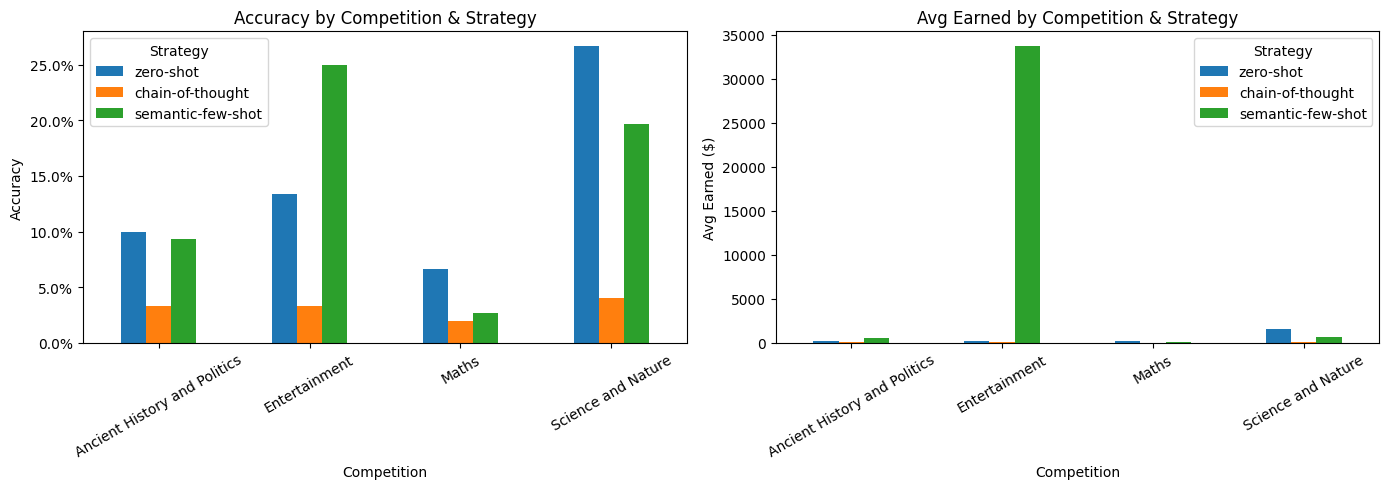

In [72]:
plot_rows = []
for strategy_name, comps in runs_log.items():
    if strategy_name == 'random':
        continue
    for comp_name, data in comps.items():
        all_games = [g for r in data['runs'] for g in r['games']]
        plot_rows.append({
            'Strategy':    strategy_name,
            'Competition': comp_name,
            'Accuracy':    sum(g['accuracy'] for g in all_games) / len(all_games),
            'Avg earned':  sum(g['earned'] for g in all_games) / len(all_games),
            'Avg level':   sum(g['reached_level'] for g in all_games) / len(all_games),
        })

plot_df     = pd.DataFrame(plot_rows)
strat_names = plot_df['Strategy'].unique().tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pivot_acc = plot_df.pivot(index='Competition', columns='Strategy', values='Accuracy')
pivot_acc = pivot_acc.reindex(columns=strat_names)
pivot_acc.plot(kind='bar', ax=axes[0], rot=30)
axes[0].set_title('Accuracy by Competition & Strategy')
axes[0].set_ylabel('Accuracy')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[0].legend(title='Strategy')

pivot_earn = plot_df.pivot(index='Competition', columns='Strategy', values='Avg earned')
pivot_earn = pivot_earn.reindex(columns=strat_names)
pivot_earn.plot(kind='bar', ax=axes[1], rot=30)
axes[1].set_title('Avg Earned by Competition & Strategy')
axes[1].set_ylabel('Avg Earned ($)')
axes[1].legend(title='Strategy')

plt.tight_layout()
plt.savefig('analysis_accuracy_earned.png', dpi=150, bbox_inches='tight')
plt.show()

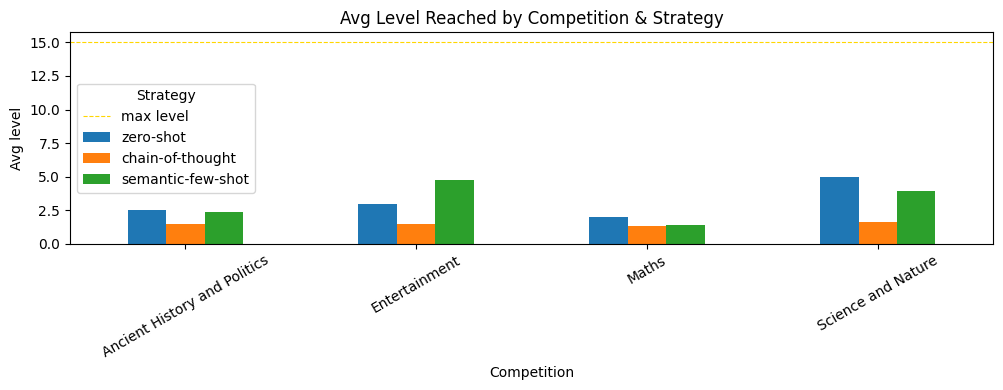

In [73]:
fig, ax = plt.subplots(figsize=(10, 4))

pivot_lvl = plot_df.pivot(index='Competition', columns='Strategy', values='Avg level')
pivot_lvl = pivot_lvl.reindex(columns=strat_names)
pivot_lvl.plot(kind='bar', ax=ax, rot=30)
ax.set_title('Avg Level Reached by Competition & Strategy')
ax.set_ylabel('Avg level')
ax.axhline(15, color='gold', linestyle='--', linewidth=0.8, label='max level')
ax.legend(title='Strategy')

plt.tight_layout()
plt.savefig('analysis_avg_level.png', dpi=150, bbox_inches='tight')
plt.show()